## Student Academic Performance Prediction

## 1. Importing Libraries

In [2]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Importing and Understanding Data

In [3]:
df=pd.read_csv("../dataset/student-mat.csv", sep=";")

In [4]:
print(df.head())

  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]


In [5]:
print("Shape:", df.shape)

Shape: (395, 33)


In [6]:
print("Missing Values:")
print(df.isnull().sum().sum())

Missing Values:
0


In [7]:
print("Column Names:")
print(df.columns)

Column Names:
Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='str')


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

In [9]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


## 3. Exploratory Data Analysis (EDA)

In [10]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [11]:
print("Numerical Columns:")
print(df.select_dtypes(include=np.number).columns)

Numerical Columns:
Index(['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel',
       'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2',
       'G3'],
      dtype='str')


In [12]:
print("Categorical Columns:")
print(df.select_dtypes(include="object").columns)

Categorical Columns:
Index(['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob',
       'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities',
       'nursery', 'higher', 'internet', 'romantic'],
      dtype='str')


C:\Users\dhima\AppData\Local\Temp\ipykernel_22404\2476768912.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.select_dtypes(include="object").columns)


#### 3a. Calculating Data Statistics

In [13]:
numerical_df = df.select_dtypes(include=np.number)
print(numerical_df.columns)

Index(['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel',
       'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2',
       'G3'],
      dtype='str')


In [14]:
numerical_df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


#### 3b. Data Visualization

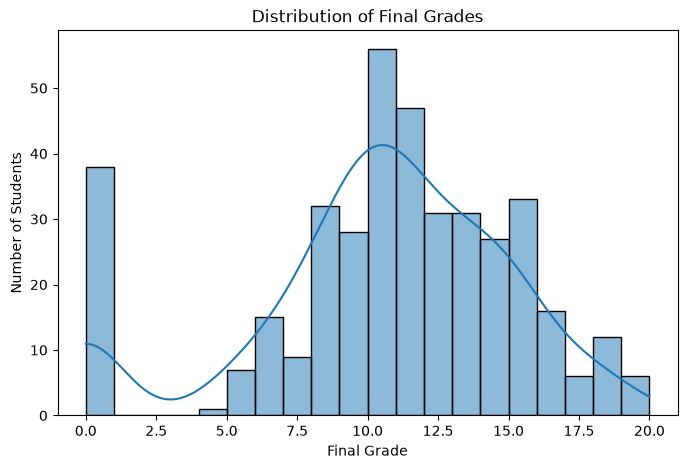

In [15]:
plt.figure(figsize=(8, 5))
sns.histplot(df["G3"], bins=20, kde=True)
plt.title("Distribution of Final Grades")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")
plt.show()

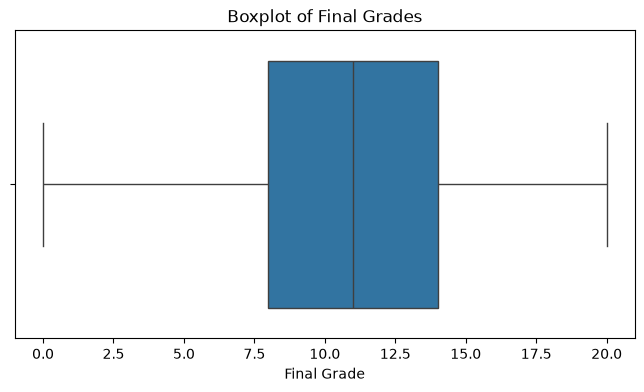

In [16]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["G3"])
plt.title("Boxplot of Final Grades")
plt.xlabel("Final Grade")
plt.show()

#### Observations from Grade Distribution

1. Most students scored between 8 and 15 in their final grades.
2. The median final grade is approximately 11.
3. The middle 50% of students scored between 8 and 14.
4. Some students received 0 marks, indicating very low academic performance.
5. The grades are distributed across the range of 0 to 20.

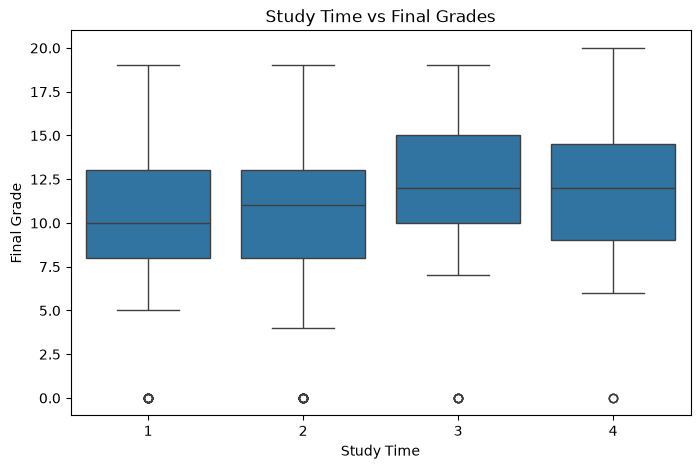

In [19]:
plt.figure(figsize=(8, 5))
sns.boxplot(x="studytime", y="G3", data=df)

plt.title("Study Time vs Final Grades")
plt.xlabel("Study Time")
plt.ylabel("Final Grade")

plt.show()

#### Graph Explanation 

1. Less than 2 hours
2. 2 to 5 hours
3. 5 to 10 hours
4. More than 10 hours

#### Observations:

1. Study-time category 3 (5–10 hours per week) has the highest median final grade.
2. Students in different study-time categories show variations in their final grades.
3. More study time does not necessarily guarantee higher final grades.

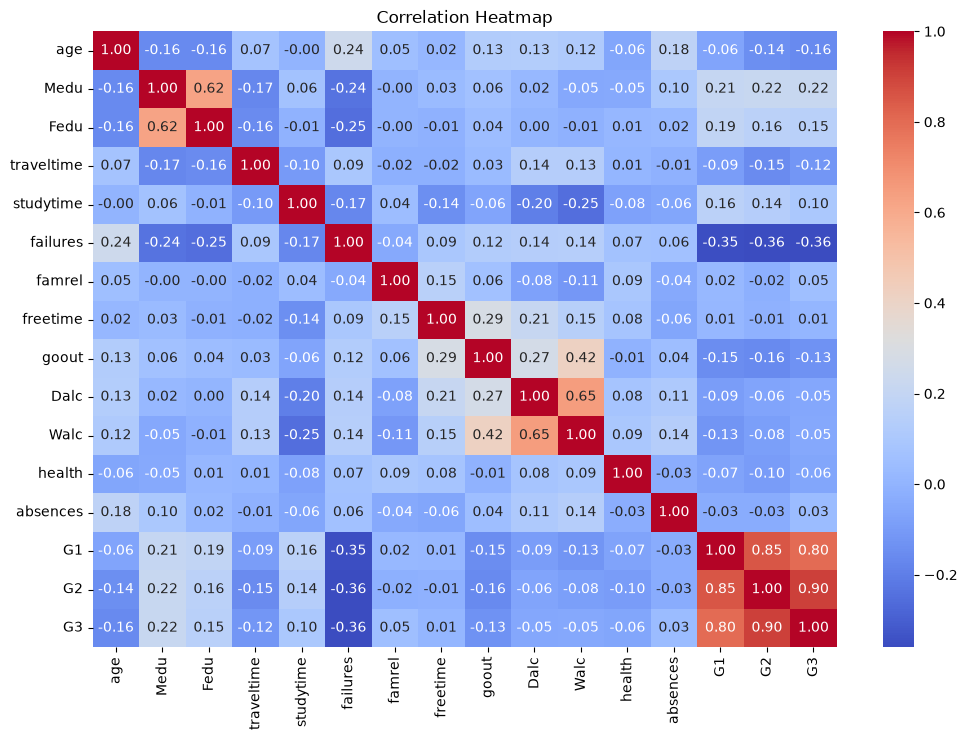

In [20]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [21]:
corr = df.corr(numeric_only=True)
print(corr["G3"].sort_values(ascending=False))

G3            1.000000
G2            0.904868
G1            0.801468
Medu          0.217147
Fedu          0.152457
studytime     0.097820
famrel        0.051363
absences      0.034247
freetime      0.011307
Walc         -0.051939
Dalc         -0.054660
health       -0.061335
traveltime   -0.117142
goout        -0.132791
age          -0.161579
failures     -0.360415
Name: G3, dtype: float64


In [22]:
print(df.describe(include="object"))

       school  sex address famsize Pstatus   Mjob   Fjob  reason guardian  \
count     395  395     395     395     395    395    395     395      395   
unique      2    2       2       2       2      5      5       4        3   
top        GP    F       U     GT3       T  other  other  course   mother   
freq      349  208     307     281     354    141    217     145      273   

       schoolsup famsup paid activities nursery higher internet romantic  
count        395    395  395        395     395    395      395      395  
unique         2      2    2          2       2      2        2        2  
top           no    yes   no        yes     yes    yes      yes       no  
freq         344    242  214        201     314    375      329      263  


C:\Users\dhima\AppData\Local\Temp\ipykernel_22404\1129007761.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.describe(include="object"))


#### 3c. Distribution of Final Grades (G3) – Frequency Count

In [23]:
print(df["G3"].value_counts().sort_index())

G3
0     38
4      1
5      7
6     15
7      9
8     32
9     28
10    56
11    47
12    31
13    31
14    27
15    33
16    16
17     6
18    12
19     5
20     1
Name: count, dtype: int64


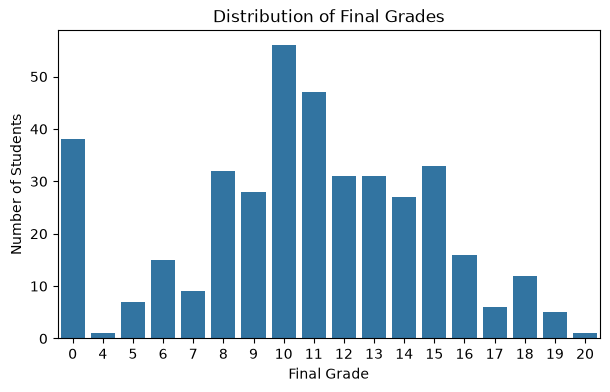

In [24]:
plt.figure(figsize=(7, 4))
sns.countplot(x="G3", data=df)
plt.title("Distribution of Final Grades")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")
plt.show()

## 4. Data Preprocessing and Feature Selection

In [37]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate records:", df.duplicated().sum())
print("Original shape:", df.shape)

Missing values: 0
Duplicate records: 0
Original shape: (395, 33)


In [38]:
def categorize_grade(grade):
    if grade == 0:
        return 0      
    elif grade <= 9:
        return 1      
    elif grade <= 13:
        return 2     
    else:
        return 3     

df["Performance"] = df["G3"].apply(categorize_grade)

In [39]:
print(df["Performance"].value_counts().sort_index())
print(df["Performance"].value_counts(normalize=True).round(2).sort_index())

Performance
0     38
1     92
2    165
3    100
Name: count, dtype: int64
Performance
0    0.10
1    0.23
2    0.42
3    0.25
Name: proportion, dtype: float64


In [51]:
X = df.drop(columns=["G1", "G2", "G3", "Performance"])
X["absences_zero"]=(X["absences"] == 0).astype("int64")
y = df["Performance"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

Input features shape: (395, 31)
Target shape: (395,)


In [52]:
numerical_cols = X.select_dtypes(include=["int64", "float64"]).columns
categorical_cols = X.select_dtypes(include=["object"]).columns

print("Numerical features:", list(numerical_cols))
print("Categorical features:", list(categorical_cols))

Numerical features: ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'absences_zero']
Categorical features: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


C:\Users\dhima\AppData\Local\Temp\ipykernel_22404\938157982.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include=["object"]).columns


## 4. Train-Test Split

In [53]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape, "Test:", X_test.shape)
print(y_train.value_counts(normalize=True).round(2).sort_index())
print(y_test.value_counts(normalize=True).round(2).sort_index())

Train: (316, 31) Test: (79, 31)
Performance
0    0.09
1    0.23
2    0.42
3    0.25
Name: proportion, dtype: float64
Performance
0    0.10
1    0.23
2    0.42
3    0.25
Name: proportion, dtype: float64


In [54]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numerical_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols),
])

X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
print("Processed train:", X_train_p.shape, "Processed test:", X_test_p.shape)

Processed train: (316, 57) Processed test: (79, 57)


In [55]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)
weights = compute_class_weight("balanced", classes=classes, y=y_train)
class_weights = {int(k): float(v) for k, v in zip(classes, weights)}
print(class_weights)

{0: 2.6333333333333333, 1: 1.0675675675675675, 2: 0.5984848484848485, 3: 0.9875}


In [56]:
zero_students = df[df["Performance"] == 0]
others = df[df["Performance"] != 0]
print("Class 0 with absences == 0:", (zero_students["absences"] == 0).mean().round(2))
print("Other classes with absences == 0:", (others["absences"] == 0).mean().round(2))

Class 0 with absences == 0: 1.0
Other classes with absences == 0: 0.22


## 5. DNN Architecture 

In [57]:
import random
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [59]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_p, y_train, test_size=0.2, random_state=SEED, stratify=y_train
)

print("Train:", X_tr.shape, "Validation:", X_val.shape)
print("Test :", X_test_p.shape)

Train: (252, 57) Validation: (64, 57)
Test : (79, 57)


#### Model

In [60]:
def build_model(input_dim, n_classes, units1=64, units2=32,
                dropout=0.3, lr=0.001, l2=1e-3):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(units1, activation="relu",
                     kernel_regularizer=regularizers.l2(l2)),
        layers.Dropout(dropout),
        layers.Dense(units2, activation="relu",
                     kernel_regularizer=regularizers.l2(l2)),
        layers.Dropout(dropout),
        layers.Dense(n_classes, activation="softmax"),
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

In [61]:
model = build_model(input_dim=X_train_p.shape[1], n_classes=y.nunique())
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         3,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,924 (23.14 KB)

 Trainable params: 5,924 (23.14 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Model Training

In [62]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=20, restore_best_weights=True
)

history = model.fit(
    X_tr, y_tr,
    validation_data=(X_val, y_val),
    epochs=200,
    batch_size=16,
    class_weight=class_weights,
    callbacks=[early_stop],
    verbose=1,
)

print("Stopped at epoch:", len(history.history["loss"]))
print("Best val loss:", round(min(history.history["val_loss"]), 4))

Epoch 1/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.2183 - loss: 1.7216 - val_accuracy: 0.1562 - val_loss: 1.5648
Epoch 2/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.1984 - loss: 1.5993 - val_accuracy: 0.2969 - val_loss: 1.5093
Epoch 3/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.2540 - loss: 1.4994 - val_accuracy: 0.3438 - val_loss: 1.4900
Epoch 4/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.2778 - loss: 1.4768 - val_accuracy: 0.4219 - val_loss: 1.4755
Epoch 5/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.2778 - loss: 1.4500 - val_accuracy: 0.3906 - val_loss: 1.4577
Epoch 6/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.3413 - loss: 1.3909 - val_accuracy: 0.4062 - val_loss: 1.4366
Epoch 7/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.3452 - loss: 1.3788 - val_accuracy: 0.4531 - val_loss: 1.4051
Epoch 8/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.4048 - loss: 1.3206 - val_accuracy: 0.

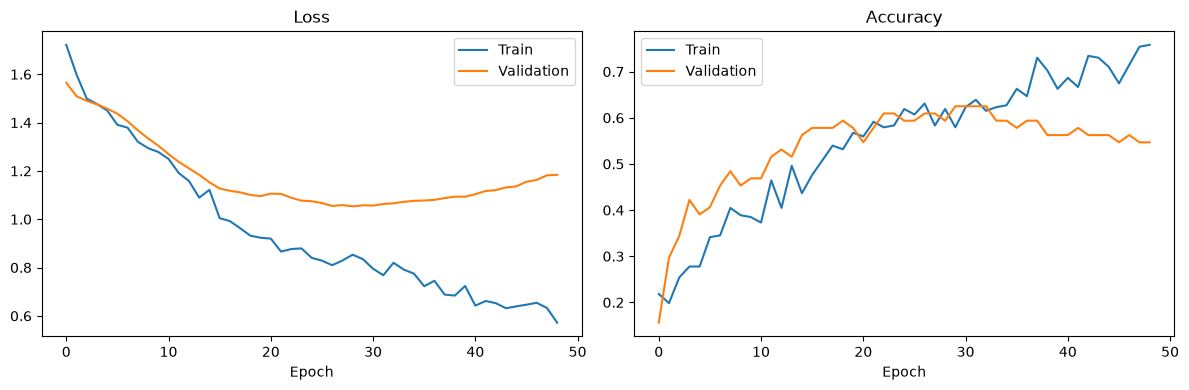

In [63]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["loss"], label="Train")
axes[0].plot(history.history["val_loss"], label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="Train")
axes[1].plot(history.history["val_accuracy"], label="Validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
              precision    recall  f1-score   support

 0: No final       0.29      0.25      0.27         8
      1: Low       0.62      0.44      0.52        18
   2: Medium       0.61      0.42      0.50        33
     3: High       0.39      0.70      0.50        20

    accuracy                           0.48        79
   macro avg       0.47      0.45      0.45        79
weighted avg       0.52      0.48      0.48        79

Macro F1: 0.446


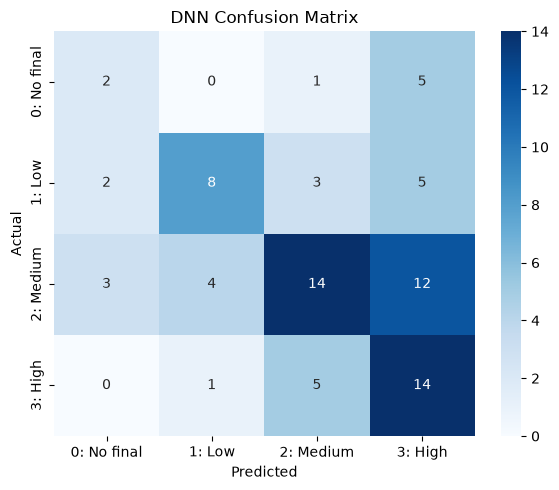

In [64]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import seaborn as sns

target_names = ["0: No final", "1: Low", "2: Medium", "3: High"]

y_pred = np.argmax(model.predict(X_test_p), axis=1)

print(classification_report(y_test, y_pred, target_names=target_names, zero_division=0))
print("Macro F1:", round(f1_score(y_test, y_pred, average="macro"), 3))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=target_names, yticklabels=target_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("DNN Confusion Matrix")
plt.tight_layout()
plt.show()

In [65]:
import pandas as pd
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import accuracy_score, f1_score
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42),
    "SVM (RBF)": SVC(class_weight="balanced", random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []

for name, clf in models.items():
    pipe = Pipeline([("prep", clone(preprocessor)), ("clf", clf)])

    cv_res = cross_validate(pipe, X_train, y_train, cv=cv,
                            scoring=["accuracy", "f1_macro"])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)

    rows.append({
        "Model": name,
        "CV accuracy": round(cv_res["test_accuracy"].mean(), 3),
        "CV macro F1": round(cv_res["test_f1_macro"].mean(), 3),
        "Test accuracy": round(accuracy_score(y_test, pred), 3),
        "Test macro F1": round(f1_score(y_test, pred, average="macro"), 3),
    })

comparison = pd.DataFrame(rows)
print(comparison)

                 Model  CV accuracy  CV macro F1  Test accuracy  Test macro F1
0    Majority baseline        0.418        0.147          0.418          0.147
1  Logistic Regression        0.516        0.530          0.430          0.429
2        Random Forest        0.491        0.523          0.430          0.401
3            SVM (RBF)        0.481        0.501          0.443          0.442


In [66]:
from sklearn.model_selection import GridSearchCV

grids = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, class_weight="balanced"),
        {"clf__C": [0.01, 0.1, 1, 10]}),
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced", random_state=42),
        {"clf__n_estimators": [200, 400],
         "clf__max_depth": [3, 5, 8, None],
         "clf__min_samples_leaf": [1, 3, 5]}),
    "SVM (RBF)": (
        SVC(class_weight="balanced", random_state=42),
        {"clf__C": [0.1, 1, 10], "clf__gamma": ["scale", 0.01, 0.001]}),
}

tuned_rows, best_models = [], {}
for name, (clf, grid) in grids.items():
    pipe = Pipeline([("prep", clone(preprocessor)), ("clf", clf)])
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="f1_macro", n_jobs=-1)
    gs.fit(X_train, y_train)
    pred = gs.predict(X_test)
    best_models[name] = gs.best_estimator_
    tuned_rows.append({
        "Model": name + " (tuned)",
        "Best params": gs.best_params_,
        "CV macro F1": round(gs.best_score_, 3),
        "Test accuracy": round(accuracy_score(y_test, pred), 3),
        "Test macro F1": round(f1_score(y_test, pred, average="macro"), 3),
    })

print(pd.DataFrame(tuned_rows).to_string())

                         Model                                                                     Best params  CV macro F1  Test accuracy  Test macro F1
0  Logistic Regression (tuned)                                                                 {'clf__C': 0.1}        0.542          0.443          0.443
1        Random Forest (tuned)  {'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 200}        0.538          0.418          0.387
2            SVM (RBF) (tuned)                                               {'clf__C': 1, 'clf__gamma': 0.01}        0.538          0.430          0.426


In [67]:
dnn_pred = np.argmax(model.predict(X_test_p), axis=1)
dnn_row = {
    "Model": "DNN",
    "Test accuracy": round(accuracy_score(y_test, dnn_pred), 3),
    "Test macro F1": round(f1_score(y_test, dnn_pred, average="macro"), 3),
}
print(dnn_row)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
{'Model': 'DNN', 'Test accuracy': 0.481, 'Test macro F1': 0.446}
